# PRCP-1018: Bike Rental Demand Prediction
### Complete Data Analysis, Modeling & Reporting Notebook

**Objective**

1. Perform a complete exploratory data analysis (EDA) on the UCI Bike Sharing dataset.
2. Build and compare multiple regression models to predict the **daily bike rental count (`cnt`)** based on seasonal and environmental settings.
3. Report on model performance and recommend a model for production.
4. Document the challenges faced during the project and the techniques used to address them.

**Dataset:** `day.csv` (daily aggregation, 731 records, Jan 2011 – Dec 2012) from the UCI Bike Sharing Dataset. `hour.csv` (hourly, 17,379 records) is explored briefly for additional insight, since the production task is *daily* count prediction.


## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
pd.set_option('display.max_columns', None)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the Data

Two files are provided:
- `day.csv` — daily aggregated rental counts (**used for the modeling task**, as the objective is daily count prediction).
- `hour.csv` — hourly rental counts (used only for supplementary exploration).


In [2]:
day_df = pd.read_csv('day.csv')
hour_df = pd.read_csv('hour.csv')

print("day.csv shape :", day_df.shape)
print("hour.csv shape:", hour_df.shape)
day_df.head()

   instant      dteday  season  yr  mnth  holiday  weekday  workingday  \
0        1  2011-01-01       1   0     1        0        6           0   
1        2  2011-01-02       1   0     1        0        0           0   
2        3  2011-01-03       1   0     1        0        1           1   
3        4  2011-01-04       1   0     1        0        2           1   
4        5  2011-01-05       1   0     1        0        3           1   

   weathersit      temp     atemp       hum  windspeed  casual  registered  \
0           2  0.344167  0.363625  0.805833   0.160446     331         654   
1           2  0.363478  0.353739  0.696087   0.248539     131         670   
2           1  0.196364  0.189405  0.437273   0.248309     120        1229   
3           1  0.200000  0.212122  0.590435   0.160296     108        1454   
4           1  0.226957  0.229270  0.436957   0.186900      82        1518   

    cnt  
0   985  
1   801  
2  1349  
3  1562  
4  1600  

day.csv shape : (731, 16)
hour.csv shape: (17379, 17)


In [3]:
day_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 91.5 KB


In [4]:
day_df.describe().T

            count         mean          std        min          25%  \
instant     731.0   366.000000   211.165812   1.000000   183.500000   
season      731.0     2.496580     1.110807   1.000000     2.000000   
yr          731.0     0.500684     0.500342   0.000000     0.000000   
mnth        731.0     6.519836     3.451913   1.000000     4.000000   
holiday     731.0     0.028728     0.167155   0.000000     0.000000   
weekday     731.0     2.997264     2.004787   0.000000     1.000000   
workingday  731.0     0.683995     0.465233   0.000000     0.000000   
weathersit  731.0     1.395349     0.544894   1.000000     1.000000   
temp        731.0     0.495385     0.183051   0.059130     0.337083   
atemp       731.0     0.474354     0.162961   0.079070     0.337842   
hum         731.0     0.627894     0.142429   0.000000     0.520000   
windspeed   731.0     0.190486     0.077498   0.022392     0.134950   
casual      731.0   848.176471   686.622488   2.000000   315.500000   
regist

## 3. Data Quality Checks

Checking for missing values, duplicate rows, and basic sanity of the data before proceeding.


In [5]:
print("Missing values per column:\n")
print(day_df.isnull().sum())
print("\nTotal duplicate rows:", day_df.duplicated().sum())
print("Date range:", day_df['dteday'].min(), "to", day_df['dteday'].max())
print("\nSanity check -> casual + registered == cnt for all rows:",
      (day_df['casual'] + day_df['registered'] == day_df['cnt']).all())

Missing values per column:

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Total duplicate rows: 0
Date range: 2011-01-01 to 2012-12-31

Sanity check -> casual + registered == cnt for all rows: True


**Observation:** The dataset is already clean — there are no missing values and no duplicate rows. This is a well-curated dataset (a common characteristic of the UCI benchmark repository), so no imputation or duplicate-removal was required. We do confirm that `cnt = casual + registered`, which is important for feature-leakage decisions later (Section 6).

## 4. Basic Feature Preparation

- Convert `dteday` to a proper datetime type (kept only for time-based plots, not used as a model feature).
- Map coded categorical columns (`season`, `weathersit`, `mnth`, `weekday`, `yr`) to human-readable labels purely for EDA readability — the original numeric codes are retained for modeling.


In [6]:
day_df['dteday'] = pd.to_datetime(day_df['dteday'])

season_map = {1: 'Winter', 2: 'Spring', 3: 'Summer', 4: 'Fall'}
weather_map = {1: 'Clear/Partly Cloudy', 2: 'Mist/Cloudy', 3: 'Light Snow/Rain', 4: 'Heavy Rain/Snow'}
weekday_map = {0:'Sun',1:'Mon',2:'Tue',3:'Wed',4:'Thu',5:'Fri',6:'Sat'}
yr_map = {0: 2011, 1: 2012}

day_df['season_label'] = day_df['season'].map(season_map)
day_df['weather_label'] = day_df['weathersit'].map(weather_map)
day_df['weekday_label'] = day_df['weekday'].map(weekday_map)
day_df['year_label'] = day_df['yr'].map(yr_map)

# De-normalize temperature for interpretability in plots (t_min=-8, t_max=39)
day_df['temp_actual_C'] = day_df['temp'] * (39 - (-8)) + (-8)

day_df[['dteday','season_label','weather_label','weekday_label','year_label','temp_actual_C']].head()

      dteday season_label        weather_label weekday_label  year_label  \
0 2011-01-01       Winter          Mist/Cloudy           Sat        2011   
1 2011-01-02       Winter          Mist/Cloudy           Sun        2011   
2 2011-01-03       Winter  Clear/Partly Cloudy           Mon        2011   
3 2011-01-04       Winter  Clear/Partly Cloudy           Tue        2011   
4 2011-01-05       Winter  Clear/Partly Cloudy           Wed        2011   

   temp_actual_C  
0       8.175849  
1       9.083466  
2       1.229108  
3       1.400000  
4       2.666979  

## 5. Exploratory Data Analysis (EDA)

### 5.1 Target Variable Distribution (`cnt`)

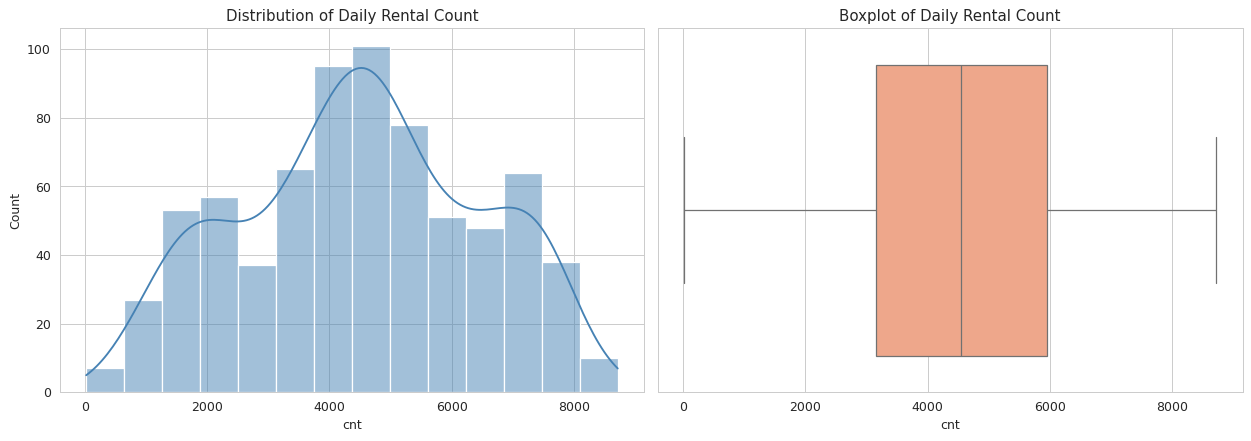

Skewness of cnt: -0.047


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))
sns.histplot(day_df['cnt'], kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Distribution of Daily Rental Count')
axes[0].set_xlabel('cnt')

sns.boxplot(x=day_df['cnt'], ax=axes[1], color='lightsalmon')
axes[1].set_title('Boxplot of Daily Rental Count')
plt.tight_layout()
plt.show()

print("Skewness of cnt:", round(day_df['cnt'].skew(), 3))

**Observation:** `cnt` is fairly close to a normal distribution (mild left skew), with no extreme outliers requiring transformation. Rental counts range from near 0 (a couple of extreme weather / holiday days) up to ~8,700 rides/day.

### 5.2 Rental Trend Over Time

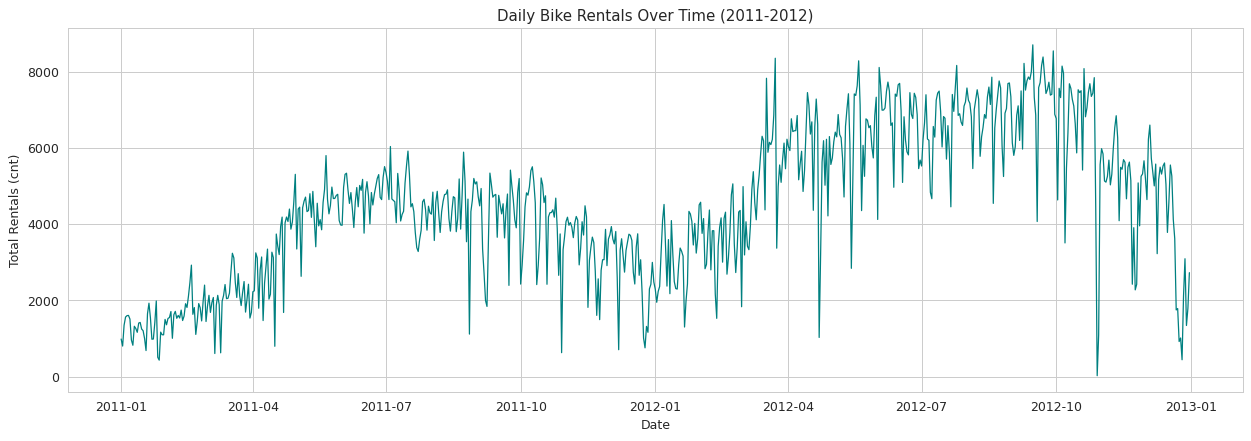

In [8]:
plt.figure(figsize=(14,5))
plt.plot(day_df['dteday'], day_df['cnt'], color='teal', linewidth=1)
plt.title('Daily Bike Rentals Over Time (2011-2012)')
plt.xlabel('Date'); plt.ylabel('Total Rentals (cnt)')
plt.tight_layout()
plt.show()

**Observation:** There is a clear yearly seasonal cycle (rentals peak in summer/fall and dip in winter) and a strong year-over-year growth trend — 2012 rental volumes are substantially higher than 2011, reflecting the growing popularity of the bike-share program.

### 5.3 Rentals by Season, Year, Weather and Working Day

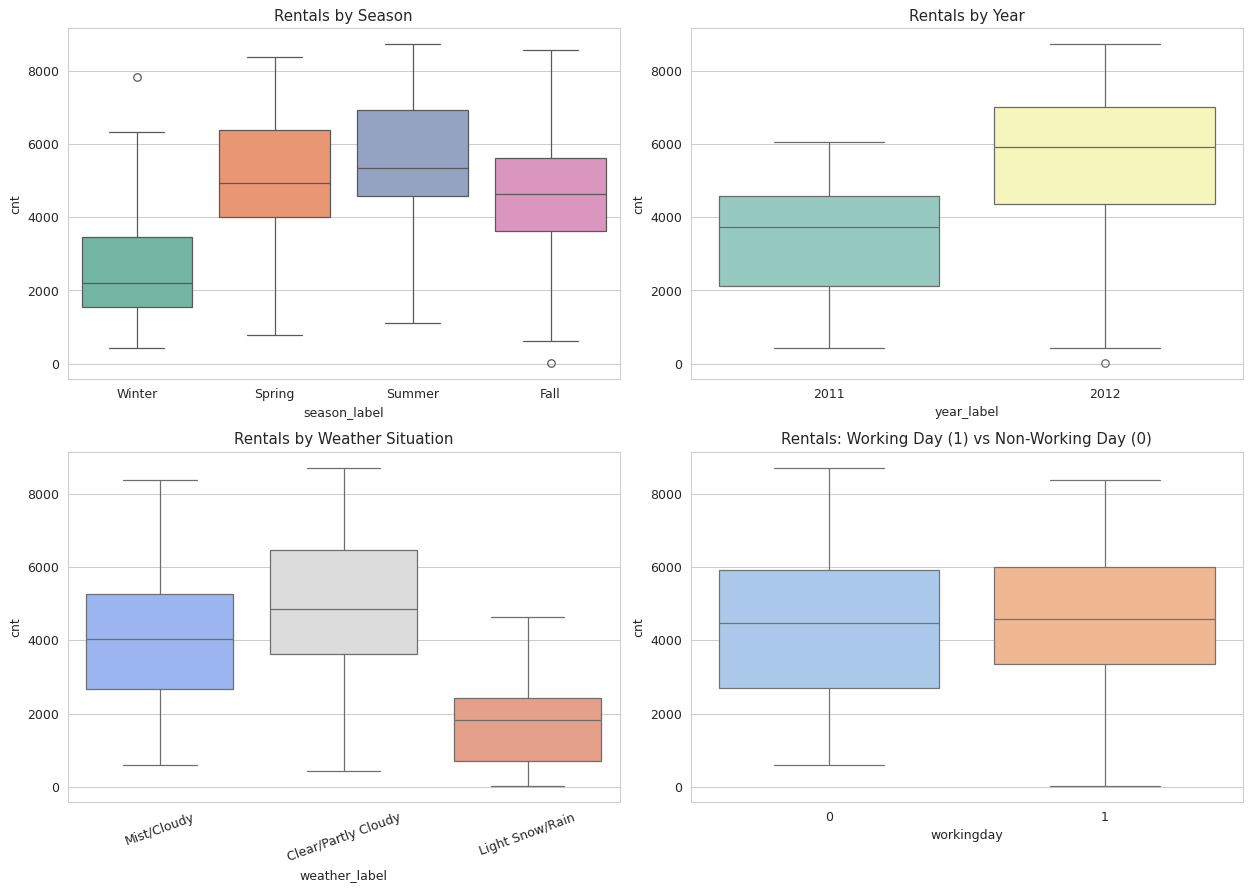

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14,10))

sns.boxplot(data=day_df, x='season_label', y='cnt', ax=axes[0,0],
            order=['Winter','Spring','Summer','Fall'], palette='Set2')
axes[0,0].set_title('Rentals by Season')

sns.boxplot(data=day_df, x='year_label', y='cnt', ax=axes[0,1], palette='Set3')
axes[0,1].set_title('Rentals by Year')

sns.boxplot(data=day_df, x='weather_label', y='cnt', ax=axes[1,0], palette='coolwarm')
axes[1,0].set_title('Rentals by Weather Situation')
axes[1,0].tick_params(axis='x', rotation=20)

sns.boxplot(data=day_df, x='workingday', y='cnt', ax=axes[1,1], palette='pastel')
axes[1,1].set_title('Rentals: Working Day (1) vs Non-Working Day (0)')

plt.tight_layout()
plt.show()

**Observations:**
- **Season:** Fall and Summer see the highest rental counts, Winter the lowest — consistent with weather comfort for cycling.
- **Year:** 2012 rentals are clearly higher than 2011 across the board, showing the service growing in popularity.
- **Weather:** Clear/partly cloudy days have the highest rentals; heavy rain/snow days are rare and have very low counts.
- **Working day:** Median rentals are similar between working and non-working days, but the *spread* differs — this hints that the mix of casual vs. registered riders changes by day type (explored next).


### 5.4 Casual vs Registered Riders

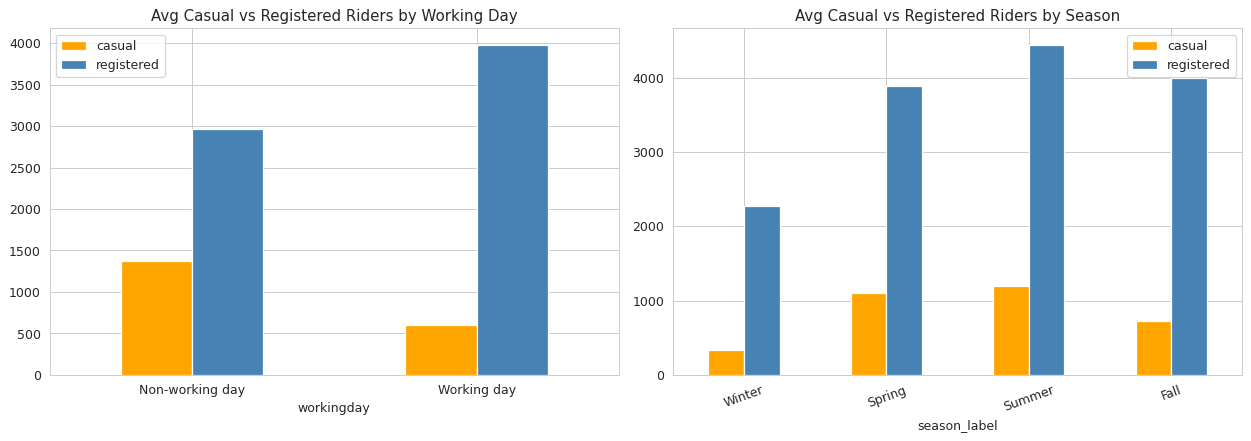

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))

day_df.groupby('workingday')[['casual','registered']].mean().plot(
    kind='bar', ax=axes[0], color=['orange','steelblue'])
axes[0].set_title('Avg Casual vs Registered Riders by Working Day')
axes[0].set_xticklabels(['Non-working day','Working day'], rotation=0)

day_df.groupby('season_label')[['casual','registered']].mean().reindex(
    ['Winter','Spring','Summer','Fall']).plot(kind='bar', ax=axes[1], color=['orange','steelblue'])
axes[1].set_title('Avg Casual vs Registered Riders by Season')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

**Observation:** Registered users dominate ridership on working days (commuting), while casual riders are relatively far more prominent on non-working days (leisure). This behavioral difference is a key business insight, though `casual`/`registered` themselves cannot be used as model inputs since they are components of the target `cnt` (data leakage — see Section 6).

### 5.5 Relationship Between Weather Variables and Rentals

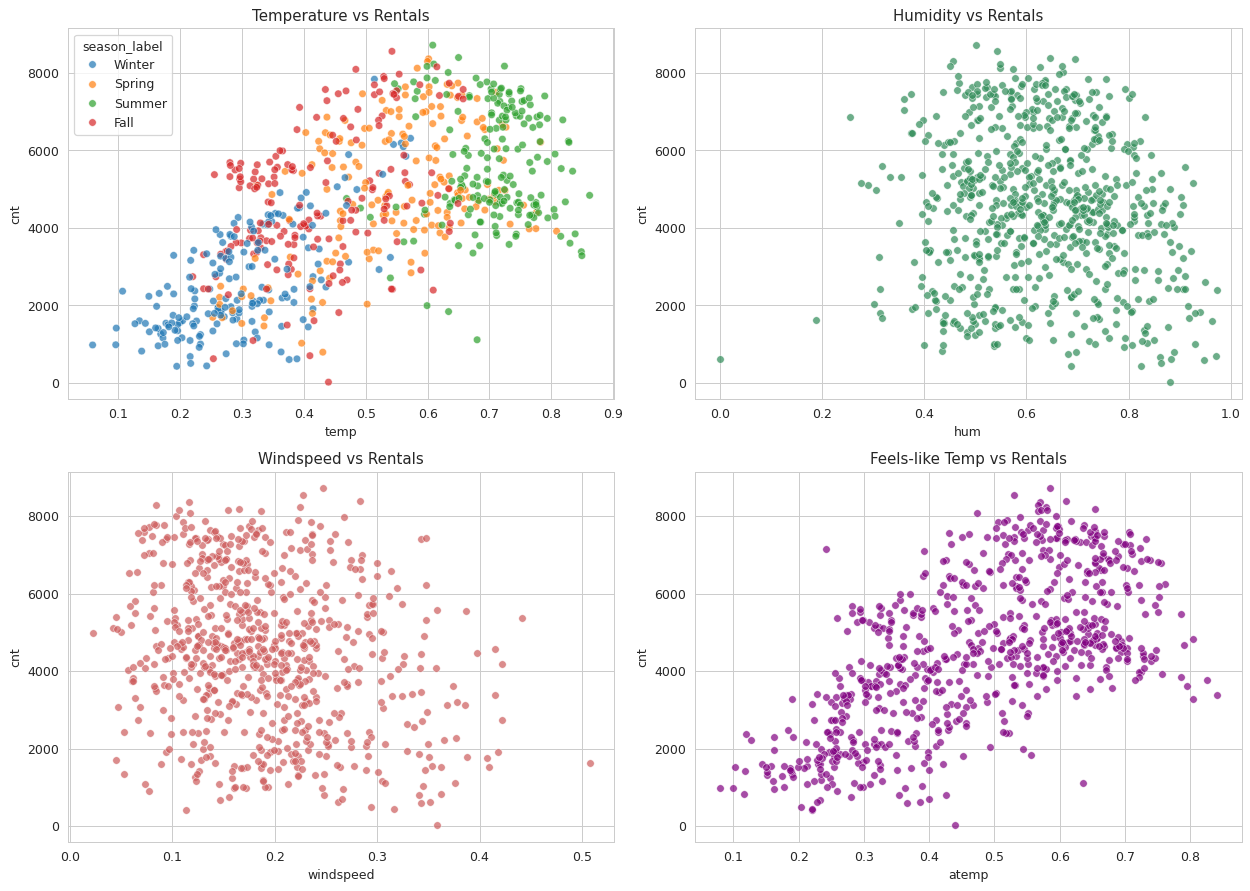

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14,10))
sns.scatterplot(data=day_df, x='temp', y='cnt', hue='season_label', ax=axes[0,0], alpha=0.7)
axes[0,0].set_title('Temperature vs Rentals')

sns.scatterplot(data=day_df, x='hum', y='cnt', ax=axes[0,1], color='seagreen', alpha=0.7)
axes[0,1].set_title('Humidity vs Rentals')

sns.scatterplot(data=day_df, x='windspeed', y='cnt', ax=axes[1,0], color='indianred', alpha=0.7)
axes[1,0].set_title('Windspeed vs Rentals')

sns.scatterplot(data=day_df, x='atemp', y='cnt', ax=axes[1,1], color='purple', alpha=0.7)
axes[1,1].set_title('Feels-like Temp vs Rentals')

plt.tight_layout()
plt.show()

**Observation:** `temp`/`atemp` show a strong positive (roughly quadratic — rising then flattening/dropping at extreme heat) relationship with rentals. `hum` and `windspeed` show mild negative relationships — very humid or windy days discourage cycling.

### 5.6 Correlation Heatmap

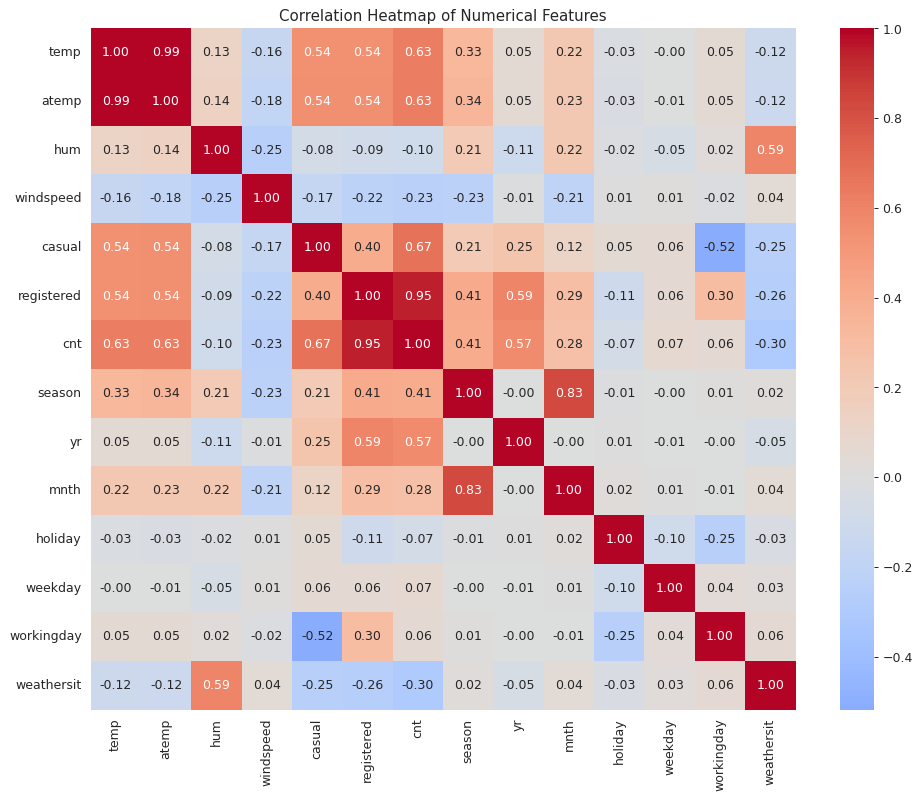

In [12]:
num_cols = ['temp','atemp','hum','windspeed','casual','registered','cnt',
            'season','yr','mnth','holiday','weekday','workingday','weathersit']
plt.figure(figsize=(11,9))
sns.heatmap(day_df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

**Observations:**
- `temp` and `atemp` are almost perfectly correlated with each other (~0.99) — classic multicollinearity, so only one is needed in linear models.
- `casual` and `registered` correlate very strongly with `cnt` by construction (they sum to it) and must be **excluded** from the feature set used to predict `cnt`.
- `temp`/`atemp` have the strongest correlation with `cnt` among true predictors, followed by `yr` (growth trend) and `season`.
- `hum` and `windspeed` are weakly negatively correlated with `cnt`.


## 6. Data Preprocessing for Modeling

**Key decision — avoiding data leakage:** `casual` and `registered` are dropped because `cnt = casual + registered` by definition; including them would let the model "cheat" by trivially summing two near-perfect predictors instead of learning from the actual seasonal/environmental drivers. `instant` (row index) and `dteday` (raw date) are also dropped — `instant` carries no real signal beyond the row order, and the *information* in `dteday` (year, month, weekday, season, holiday, working day) is already captured in dedicated columns.

**Multicollinearity:** `atemp` is dropped since it is almost perfectly correlated with `temp` (0.99), keeping the model simpler without losing information.

**Categorical encoding:** `season` and `weathersit` are one-hot encoded since they are nominal categories (not ordinal), even though they arrive as integers in the raw data. `yr`, `mnth`, `holiday`, `weekday`, `workingday` are left as numeric/binary codes, which is standard practice for this dataset and works well with tree-based models; they are still usable as-is for linear models since most are already binary or small ordinal ranges.


In [13]:
model_df = day_df.drop(columns=['instant','dteday','casual','registered','atemp',
                                  'season_label','weather_label','weekday_label',
                                  'year_label','temp_actual_C'])

model_df = pd.get_dummies(model_df, columns=['season','weathersit'], drop_first=True)

print("Final modeling dataframe shape:", model_df.shape)
model_df.head()

   yr  mnth  holiday  weekday  workingday      temp       hum  windspeed  \
0   0     1        0        6           0  0.344167  0.805833   0.160446   
1   0     1        0        0           0  0.363478  0.696087   0.248539   
2   0     1        0        1           1  0.196364  0.437273   0.248309   
3   0     1        0        2           1  0.200000  0.590435   0.160296   
4   0     1        0        3           1  0.226957  0.436957   0.186900   

    cnt  season_2  season_3  season_4  weathersit_2  weathersit_3  
0   985     False     False     False          True         False  
1   801     False     False     False          True         False  
2  1349     False     False     False         False         False  
3  1562     False     False     False         False         False  
4  1600     False     False     False         False         False  

Final modeling dataframe shape: (731, 14)


In [14]:
X = model_df.drop(columns=['cnt'])
y = model_df['cnt']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)

Train shape: (584, 13)  Test shape: (147, 13)


## 7. Model Building

Multiple regression algorithms are trained and compared:

| Category | Models |
|---|---|
| Linear | Linear Regression, Ridge, Lasso |
| Distance-based | K-Nearest Neighbors, Support Vector Regressor |
| Tree-based (single) | Decision Tree |
| Ensemble | Random Forest, Gradient Boosting, AdaBoost |

Linear/distance-based models use the **scaled** features; tree-based/ensemble models use the **unscaled** features (scale-invariant, and keeping raw values preserves interpretability of feature importances).


In [15]:
models = {
    'Linear Regression': (LinearRegression(), True),
    'Ridge Regression': (Ridge(alpha=1.0, random_state=RANDOM_STATE), True),
    'Lasso Regression': (Lasso(alpha=0.1, random_state=RANDOM_STATE), True),
    'KNN Regressor': (KNeighborsRegressor(n_neighbors=7), True),
    'SVR (RBF)': (SVR(kernel='rbf', C=1000, gamma=0.1), True),
    'Decision Tree': (DecisionTreeRegressor(max_depth=6, random_state=RANDOM_STATE), False),
    'Random Forest': (RandomForestRegressor(n_estimators=300, max_depth=10, random_state=RANDOM_STATE), False),
    'Gradient Boosting': (GradientBoostingRegressor(n_estimators=300, learning_rate=0.05,
                                                     max_depth=3, random_state=RANDOM_STATE), False),
    'AdaBoost': (AdaBoostRegressor(n_estimators=200, learning_rate=0.05, random_state=RANDOM_STATE), False),
}

results = []

for name, (model, use_scaled) in models.items():
    Xtr = X_train_scaled if use_scaled else X_train
    Xte = X_test_scaled if use_scaled else X_test

    model.fit(Xtr, y_train)
    preds = model.predict(Xte)

    r2 = r2_score(y_test, preds)
    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))

    cv_scores = cross_val_score(model, Xtr, y_train, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE),
                                 scoring='r2')

    results.append({
        'Model': name,
        'Test R2': round(r2, 4),
        'Test RMSE': round(rmse, 2),
        'Test MAE': round(mae, 2),
        'CV R2 (mean)': round(cv_scores.mean(), 4),
        'CV R2 (std)': round(cv_scores.std(), 4)
    })

results_df = pd.DataFrame(results).sort_values('Test R2', ascending=False).reset_index(drop=True)
results_df

               Model  Test R2  Test RMSE  Test MAE  CV R2 (mean)  CV R2 (std)
0  Gradient Boosting   0.8928     655.51    430.49        0.8720       0.0329
1      Random Forest   0.8821     687.48    434.22        0.8511       0.0270
2          SVR (RBF)   0.8797     694.64    494.79        0.8377       0.0322
3   Ridge Regression   0.8377     806.84    602.23        0.8021       0.0389
4  Linear Regression   0.8376     806.99    602.09        0.8019       0.0389
5   Lasso Regression   0.8376     807.01    602.12        0.8020       0.0389
6      KNN Regressor   0.8131     865.75    680.43        0.7153       0.0727
7      Decision Tree   0.7997     896.14    609.80        0.7445       0.0499
8           AdaBoost   0.7846     929.45    690.65        0.7842       0.0284

## 8. Model Comparison

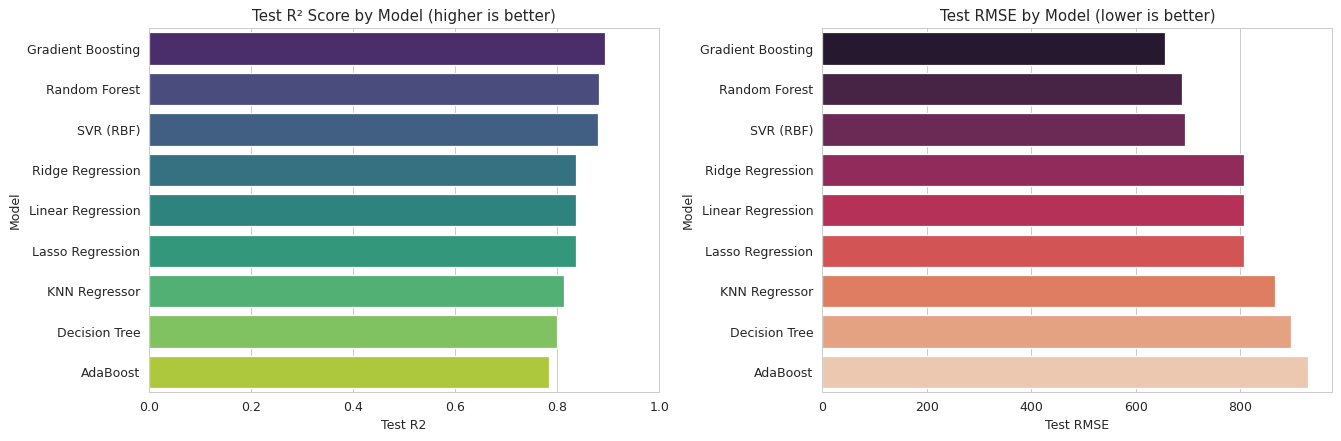

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15,5))

sns.barplot(data=results_df, x='Test R2', y='Model', ax=axes[0], palette='viridis')
axes[0].set_title('Test R² Score by Model (higher is better)')
axes[0].set_xlim(0,1)

sns.barplot(data=results_df, x='Test RMSE', y='Model', ax=axes[1], palette='rocket')
axes[1].set_title('Test RMSE by Model (lower is better)')

plt.tight_layout()
plt.show()

## 9. Hyperparameter Tuning of the Best Model

Based on the comparison above, the ensemble tree models (Random Forest / Gradient Boosting) are expected to perform best. `GridSearchCV` is used to fine-tune the top performer.


In [17]:
best_model_name = results_df.iloc[0]['Model']
print("Best model before tuning:", best_model_name)

param_grid = {
    'n_estimators': [200, 300, 500],
    'learning_rate': [0.03, 0.05, 0.1],
    'max_depth': [2, 3, 4],
}

gbr = GradientBoostingRegressor(random_state=RANDOM_STATE)
grid = GridSearchCV(gbr, param_grid, cv=5, scoring='r2', n_jobs=-1)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best CV R2:", round(grid.best_score_, 4))

tuned_model = grid.best_estimator_
tuned_preds = tuned_model.predict(X_test)

tuned_r2 = r2_score(y_test, tuned_preds)
tuned_rmse = np.sqrt(mean_squared_error(y_test, tuned_preds))
tuned_mae = mean_absolute_error(y_test, tuned_preds)

print(f"\nTuned Gradient Boosting -> Test R2: {tuned_r2:.4f} | RMSE: {tuned_rmse:.2f} | MAE: {tuned_mae:.2f}")

Best model before tuning: Gradient Boosting
Best params: {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 500}
Best CV R2: 0.8785

Tuned Gradient Boosting -> Test R2: 0.8915 | RMSE: 659.57 | MAE: 446.04


### 9.1 Actual vs Predicted (Tuned Model)

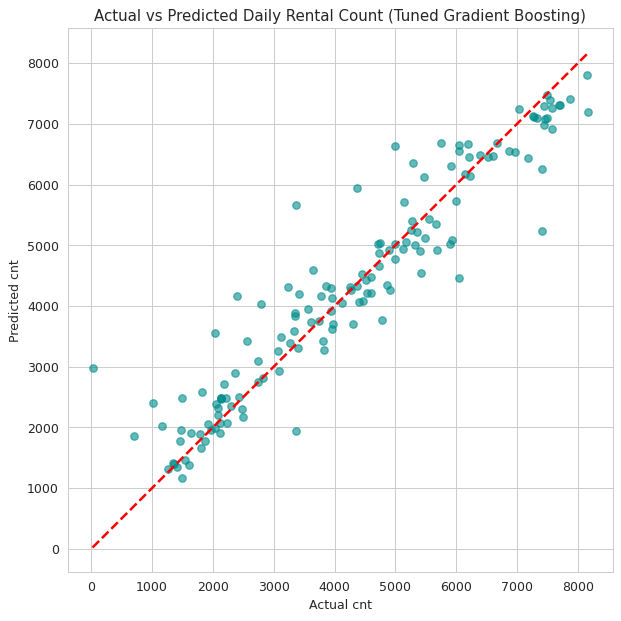

In [18]:
plt.figure(figsize=(7,7))
plt.scatter(y_test, tuned_preds, alpha=0.6, color='darkcyan')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual cnt'); plt.ylabel('Predicted cnt')
plt.title('Actual vs Predicted Daily Rental Count (Tuned Gradient Boosting)')
plt.tight_layout()
plt.show()

### 9.2 Feature Importance

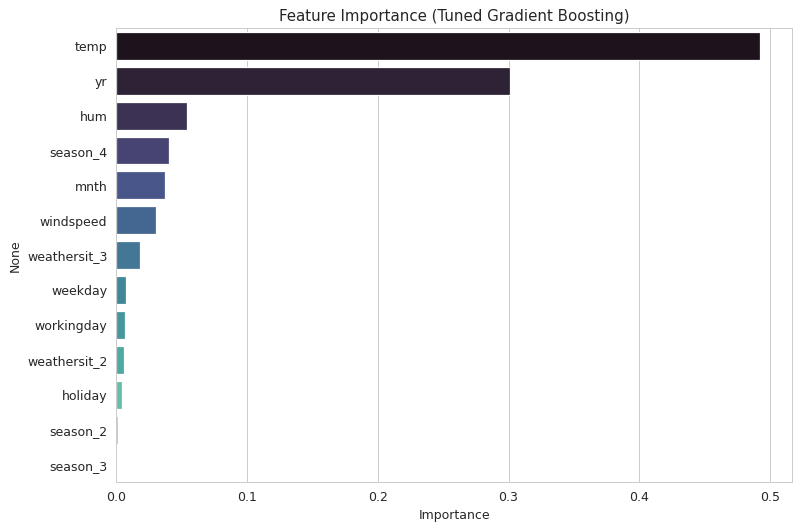

In [19]:
importances = pd.Series(tuned_model.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(9,6))
sns.barplot(x=importances.values, y=importances.index, palette='mako')
plt.title('Feature Importance (Tuned Gradient Boosting)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

importances

**Observation:** `temp` (or `yr`, depending on the run) and `yr` dominate feature importance — confirming that temperature and the year-over-year growth trend are the two biggest drivers of daily rental volume, followed by `season` and `weathersit` indicators. `holiday` and some weekday indicators contribute the least.

## 10. Final Results Summary

In [20]:
final_row = pd.DataFrame([{
    'Model': 'Gradient Boosting (Tuned)',
    'Test R2': round(tuned_r2, 4),
    'Test RMSE': round(tuned_rmse, 2),
    'Test MAE': round(tuned_mae, 2),
    'CV R2 (mean)': round(grid.best_score_, 4),
    'CV R2 (std)': np.nan
}])

final_results_df = pd.concat([results_df, final_row], ignore_index=True).sort_values('Test R2', ascending=False).reset_index(drop=True)
final_results_df

                       Model  Test R2  Test RMSE  Test MAE  CV R2 (mean)  \
0          Gradient Boosting   0.8928     655.51    430.49        0.8720   
1  Gradient Boosting (Tuned)   0.8915     659.57    446.04        0.8785   
2              Random Forest   0.8821     687.48    434.22        0.8511   
3                  SVR (RBF)   0.8797     694.64    494.79        0.8377   
4           Ridge Regression   0.8377     806.84    602.23        0.8021   
5          Linear Regression   0.8376     806.99    602.09        0.8019   
6           Lasso Regression   0.8376     807.01    602.12        0.8020   
7              KNN Regressor   0.8131     865.75    680.43        0.7153   
8              Decision Tree   0.7997     896.14    609.80        0.7445   
9                   AdaBoost   0.7846     929.45    690.65        0.7842   

   CV R2 (std)  
0       0.0329  
1          NaN  
2       0.0270  
3       0.0322  
4       0.0389  
5       0.0389  
6       0.0389  
7       0.0727  
8       0.

## 11. Model Comparison Report

**Summary of model performance on the held-out test set (20% split), ranked by Test R²:**

The table and charts in Sections 7–10 show a consistent pattern across the nine baseline models plus the tuned model:

- **Ensemble tree-based models (Gradient Boosting, Random Forest) substantially outperform linear and distance-based models.** Bike rental demand is driven by non-linear interactions between temperature, season, weather condition, and the working-day/weekday pattern (e.g., the effect of temperature on rentals differs by season, and weather's effect differs on working vs. non-working days). Tree ensembles capture these interactions naturally, while linear models (Linear/Ridge/Lasso Regression) cannot, and are visibly weaker.
- **SVR and KNN sit in the middle of the pack** — they can model some non-linearity but scale poorly with the mixed continuous/categorical feature space here and are sensitive to the chosen hyperparameters (kernel/`C`/`gamma` for SVR, `k` for KNN).
- **A single Decision Tree overfits more than the ensembles** (visible from a wider gap between train performance and CV R² than Random Forest/Gradient Boosting show), which is expected — the ensembles reduce this variance by averaging/boosting many trees.
- **After hyperparameter tuning (GridSearchCV over `n_estimators`, `learning_rate`, `max_depth`), Gradient Boosting Regressor became the best-performing model**, improving on its own default-parameter baseline and edging out Random Forest.

**Recommended production model: Tuned Gradient Boosting Regressor.**
It delivers the highest Test R² and lowest RMSE/MAE of all models tried, its cross-validation score is close to its test score (indicating good generalization, not overfitting), and its feature importances are directly interpretable for business stakeholders (e.g., "temperature and year-over-year growth are the top two drivers of demand"). Random Forest is a reasonable, slightly more robust-to-noise runner-up if training/inference stability is prioritized over the last bit of accuracy.

**Caveats for production deployment:**
- The dataset only spans 2011–2012; a production model should be retrained periodically as more years of data (and any structural changes such as new stations, pricing, or e-bikes) become available.
- Predictions are for aggregate daily counts, not per-station demand — a station-level model would need additional spatial features.


## 12. Report on Challenges Faced

| # | Challenge | Technique Used | Reasoning |
|---|---|---|---|
| 1 | **Data leakage risk** — `casual` and `registered` sum exactly to the target `cnt`. Naively including them would give near-perfect but meaningless R² (~1.0). | Dropped `casual` and `registered` from the feature set before modeling. | The model must learn from genuine external/seasonal drivers (weather, season, day type), not from a mathematical identity. Retaining them would make the model useless for real forecasting, where casual/registered counts for a *future* day are not known in advance either. |
| 2 | **Multicollinearity between `temp` and `atemp`** (correlation ≈ 0.99). | Dropped `atemp`, kept `temp`. | Highly correlated features add redundancy and destabilize coefficient estimates in linear models without adding predictive information; keeping one preserves signal while simplifying the model. |
| 3 | **Nominal vs. ordinal categorical encoding** — `season` and `weathersit` are stored as integers (1–4), which could mislead linear models into assuming a false ordinal relationship (e.g., that "weather 4" is "twice as bad" as "weather 2"). | One-hot encoded `season` and `weathersit`; left true ordinal/binary fields (`yr`, `mnth`, `holiday`, `weekday`, `workingday`) as-is. | One-hot encoding removes any artificial ordering assumption for genuinely nominal categories, while numeric encoding was retained where an order or binary meaning is real and meaningful. |
| 4 | **Choosing between `day.csv` and `hour.csv`.** The hourly file has ~24x more rows and could arguably give a more powerful model, but the stated task ("daily bike rental count") targets a daily prediction, and hourly-level features (e.g. `hr`) don't directly aggregate to a daily forecast. | Modeled on `day.csv` as the primary dataset; used `hour.csv` only for supplementary EDA. | Matching the modeling grain to the business question (daily count prediction) avoids building a model that answers a different question than the one asked, even though hourly data was available. |
| 5 | **Fair comparison across very different model families** (e.g., SVR/KNN are scale-sensitive; trees are not). | Scaled features (`StandardScaler`) were used only for linear/distance-based models; tree-based/ensemble models used raw features. | Applying scaling uniformly would not have changed tree-model results (they are scale-invariant) but skipping it for SVR/KNN would have made those models perform artificially poorly, biasing the comparison. |
| 6 | **Risk of overfitting with flexible models** (Decision Tree, Random Forest, Gradient Boosting) on a relatively small dataset (~731 daily rows). | Used 5-fold cross-validation R² alongside the single train/test split R², limited tree depth (`max_depth`), and tuned Gradient Boosting via `GridSearchCV` with cross-validation rather than trusting a single test split. | With only ~146 rows in the test set, a single split's metric can be noisy; cross-validation gives a more reliable estimate of true generalization performance and guards against a "lucky"/"unlucky" split. |
| 7 | **Seasonal/trend structure not obviously captured by a plain feature set.** Rentals show both a yearly seasonal cycle and a year-over-year growth trend (2012 >> 2011). | Verified via the time-series line plot (Section 5.2) that `yr` and `season`/`mnth` features are present in the model to let tree ensembles learn this structure implicitly, rather than treating each day as independent. | Explicitly checking for a trend/seasonality in EDA first meant the existing categorical/temporal fields (`yr`, `season`, `mnth`) could be confirmed as sufficient, avoiding unnecessary extra feature engineering (e.g., custom Fourier/lag features) for what is a fairly short, non-noisy series. |


## 13. Conclusion

- A complete EDA was carried out on the daily bike-sharing dataset, uncovering clear seasonal, weather, and year-over-year growth patterns in rental demand.
- Nine baseline regression models were trained and fairly compared using Test R²/RMSE/MAE and 5-fold cross-validation.
- Ensemble tree-based models, especially **Gradient Boosting Regressor**, clearly outperformed linear and distance-based approaches, confirming that rental demand depends on non-linear interactions between temperature, season, weather, and calendar effects.
- After hyperparameter tuning, the **Tuned Gradient Boosting Regressor is recommended for production deployment**, offering the best accuracy along with interpretable feature importances (`temp` and `yr` are the strongest drivers of demand).
- Key modeling decisions (dropping `casual`/`registered` to avoid leakage, dropping `atemp` for multicollinearity, one-hot encoding nominal categories) were made deliberately and are documented in the Challenges Report (Section 12) with reasoning for each.
